<h1>08. Random Comparisons and Final Answers</h1>

**What we do.** We answer RQ4 and then synthesize RQ1-RQ4 into one place: we compare the observed 84.5% same-field homophily and 0.453 Louvain modularity against two null models, 1,000 label shuffles and 20 degree-preserving rewired graphs, compute empirical p-values and z-scores for both, compare the network against Erdos-Renyi, Barabasi-Albert, Watts-Strogatz, and a degree-preserving configuration model, and fit a power-law tail to the degree distribution.

**What we get.** Two null-model significance tables, a network-vs-random-models comparison table, a power-law fit table, the homophily-null-distribution figure, and a consolidated table that restates the evidence for RQ1 through RQ4 in one place, built dynamically from the saved result files rather than typed in by hand.

**Why this step matters.** Every earlier notebook found a descriptive pattern: network structure predicts field, communities carry signal, hidden edges can be recovered. None of that, by itself, proves the pattern is unusual rather than an artifact of the class sizes or the degree sequence. This notebook turns "we observed X" into "X is unlikely to have happened by chance under two specific, named null hypotheses," which is the difference between a descriptive project and one that makes a statistically grounded claim.

In [1]:
from pathlib import Path
import os
import sys
import warnings

def _find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "requirements.txt").exists() and (candidate / "data").exists():
            return candidate.resolve()
    raise FileNotFoundError("Could not locate the project root")

ROOT = _find_project_root(Path.cwd())
os.chdir(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("PYTHONHASHSEED", "0")
warnings.filterwarnings("ignore", category=FutureWarning)
__name__ = "notebook_08"
print(f"Project root: {ROOT}")

Project root: C:\Users\Jimi\Desktop\github-social-network


<h2>Random comparison setup</h2>

We compare the real graph with several random versions. Some keep the graph fixed and shuffle labels; others keep node degrees but rewire edges. These checks help show whether the real patterns are stronger than simple random baselines.

<h3>Source code: <code>src/run_null_models.py</code></h3>

Compares the observed network with label-shuffle and degree-preserving null models and fits the power-law tail for RQ4.

**`imports and constants`**

Imports the external libraries and project modules this file depends on, and defines the fixed constants (seeds, budgets, thresholds) shared by every function below.

In [ ]:
# -*- coding: utf-8 -*-
"""
Null models and statistical significance of the structural findings.

Three questions, each answered against an appropriate random model:

1. Is the observed homophily (share of same-label edges) significant?
   - Null A: shuffle labels over nodes (1,000 permutations, degree structure
     and label counts preserved).
   - Null B: degree-preserving edge rewiring (double edge swaps, labels
     fixed) - controls for the degree-label correlation.

2. Is the Louvain modularity significant?
   - Compared against Louvain modularity of degree-preserving rewired graphs.

3. Which properties are reproduced by course-covered network models?
   - Erdos-Renyi, Barabasi-Albert, Watts-Strogatz small-world and a
     degree-preserving configuration-style null graph.
   - Power-law fit of the degree distribution (powerlaw package), including
     likelihood-ratio comparison against lognormal and exponential.

Outputs:
    outputs/tables/null_model_homophily.csv
    outputs/tables/null_model_modularity.csv
    outputs/tables/network_vs_random_models.csv
    outputs/tables/powerlaw_fit.csv
    outputs/figures/homophily_null_distribution.png
    outputs/figures/degree_distribution_loglog.png
"""
import time
from pathlib import Path

import sys

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

SRC_DIR = Path(__file__).resolve().parent
PROJECT_DIR = SRC_DIR.parent
sys.path.insert(0, str(SRC_DIR))

from community_analysis import detect_louvain_communities
from data_loader import load_dataset


N_LABEL_SHUFFLES = 1000
N_REWIRES = 20
N_SWAPS_PER_EDGE = 2
N_BFS_SAMPLES = 300
SEED = 42
SMALL_WORLD_REWIRING_PROBABILITY = 0.10

**`same_label_fraction`**

A vectorized homophily statistic, the fraction of edges whose endpoints share a label, implemented with NumPy array comparisons so it is fast enough to repeat over 1,000+ label-shuffle simulations.

In [ ]:
def same_label_fraction(edge_u: np.ndarray, edge_v: np.ndarray, labels: np.ndarray) -> float:
    """Fraction of edges whose endpoints share a label."""
    return float(np.mean(labels[edge_u] == labels[edge_v]))

**`sampled_average_shortest_path`**

Estimates the graph's average shortest-path length from a fixed-size random sample of BFS sources rather than computing it exactly, since an exact all-pairs computation over 37,700 nodes is too slow to repeat for every comparison graph.

In [ ]:
def sampled_average_shortest_path(G: nx.Graph, n_samples: int, rng: np.random.Generator) -> float:
    """Estimate average shortest path length via BFS from sampled sources."""
    nodes = list(G.nodes())
    sources = rng.choice(len(nodes), size=min(n_samples, len(nodes)), replace=False)
    total, count = 0.0, 0
    for idx in sources:
        lengths = nx.single_source_shortest_path_length(G, nodes[int(idx)])
        # exclude the source itself
        total += sum(lengths.values())
        count += len(lengths) - 1
    return total / count if count else float("nan")

**`empirical_upper_tail_p`**

Computes an empirical upper-tail p-value as (b+1)/(B+1), where b is the count of null simulations at least as extreme as the observed value. This finite-sample correction is why a p-value here can never be reported as exactly zero, no matter how extreme the observation is.

In [ ]:
def empirical_upper_tail_p(
    null_values: np.ndarray, observed_value: float
) -> float:
    """Finite-simulation upper-tail p-value with the (b+1)/(B+1) correction."""
    values = np.asarray(null_values, dtype=float)
    if values.size == 0:
        raise ValueError("At least one null simulation is required.")
    return float((np.sum(values >= observed_value) + 1) / (values.size + 1))

**`main`**

Runs the label-shuffle and degree-preserving null models, compares the network with ER/BA/Watts-Strogatz/configuration graphs, fits the power-law tail, and saves every RQ4 table and figure. Two null models are used for two different questions: 1,000 label shuffles ask whether the class sizes alone explain the observed homophily, while 20 degree-preserving rewired graphs ask whether the degree sequence explains it instead; both use the (b+1)/(B+1) empirical-p correction, which is why a p-value here can never be reported as exactly zero. The comparison graphs are built to match the real network as closely as each model allows and no closer: Erdos-Renyi matches the edge count exactly, while integer-m Barabasi-Albert yields about 4% more edges, close but not identical, and that mismatch is reported rather than hidden.

In [ ]:
def main() -> None:
    data_dir = PROJECT_DIR / "data"
    tables_dir = PROJECT_DIR / "outputs" / "tables"
    figures_dir = PROJECT_DIR / "outputs" / "figures"
    tables_dir.mkdir(parents=True, exist_ok=True)
    figures_dir.mkdir(parents=True, exist_ok=True)

    G, edges_df, labels_df, labels_dict = load_dataset(data_dir)
    n_nodes = G.number_of_nodes()
    n_edges = G.number_of_edges()

    labels = np.zeros(int(labels_df["id"].max()) + 1, dtype=np.int64)
    labels[labels_df["id"].to_numpy()] = labels_df["label"].to_numpy()
    edge_u = edges_df["id_1"].to_numpy(dtype=np.int64)
    edge_v = edges_df["id_2"].to_numpy(dtype=np.int64)

    rng = np.random.default_rng(SEED)

    # ------------------------------------------------------------------
    # 1) Homophily significance
    # ------------------------------------------------------------------
    observed_fraction = same_label_fraction(edge_u, edge_v, labels)
    observed_assortativity = nx.attribute_assortativity_coefficient(G, "label")
    print(f"Observed same-label fraction: {observed_fraction:.4f}")
    print(f"Observed label assortativity: {observed_assortativity:.4f}")

    # Null A: label shuffling
    print(f"Null A: {N_LABEL_SHUFFLES} label shuffles ...")
    t0 = time.time()
    shuffle_fractions = np.empty(N_LABEL_SHUFFLES)
    label_pool = labels_df["label"].to_numpy().copy()
    node_ids = labels_df["id"].to_numpy()
    for i in range(N_LABEL_SHUFFLES):
        shuffled = rng.permutation(label_pool)
        null_labels = np.zeros_like(labels)
        null_labels[node_ids] = shuffled
        shuffle_fractions[i] = same_label_fraction(edge_u, edge_v, null_labels)
    print(f"  done in {time.time() - t0:.1f}s")

    shuffle_mean = float(shuffle_fractions.mean())
    shuffle_std = float(shuffle_fractions.std(ddof=1))
    z_shuffle = (observed_fraction - shuffle_mean) / shuffle_std
    # Empirical p with the (b+1)/(B+1) correction: an empirical p-value can
    # never be exactly 0, only bounded by the number of permutations.
    p_shuffle = empirical_upper_tail_p(shuffle_fractions, observed_fraction)

    # Null B: degree-preserving rewiring (labels fixed)
    print(f"Null B: {N_REWIRES} degree-preserving rewired graphs ...")
    rewire_fractions = []
    rewire_modularities = []
    G_configuration = None
    for i in range(N_REWIRES):
        t0 = time.time()
        G_rewired = G.copy()
        nx.double_edge_swap(
            G_rewired,
            nswap=n_edges * N_SWAPS_PER_EDGE,
            max_tries=n_edges * N_SWAPS_PER_EDGE * 20,
            seed=SEED + i,
        )
        if i == 0:
            # Simple-graph configuration-style null: exact degrees are
            # retained while the endpoint pairing is randomized.
            G_configuration = G_rewired.copy()

        rewired_edges = np.array(G_rewired.edges(), dtype=np.int64)
        rewire_fractions.append(
            same_label_fraction(rewired_edges[:, 0], rewired_edges[:, 1], labels)
        )

        _, modularity = detect_louvain_communities(G_rewired, random_state=42)
        rewire_modularities.append(float(modularity))
        print(
            f"  rewire {i + 1}/{N_REWIRES}: same-label={rewire_fractions[-1]:.4f}, "
            f"modularity={rewire_modularities[-1]:.4f} ({time.time() - t0:.0f}s)"
        )

    rewire_fractions_arr = np.asarray(rewire_fractions)
    rewire_mean = float(rewire_fractions_arr.mean())
    rewire_std = float(rewire_fractions_arr.std(ddof=1))
    z_rewire = (observed_fraction - rewire_mean) / rewire_std if rewire_std else float("inf")

    homophily_df = pd.DataFrame(
        [
            {
                "null_model": "label_shuffle",
                "n_samples": N_LABEL_SHUFFLES,
                "observed": observed_fraction,
                "null_mean": shuffle_mean,
                "null_std": shuffle_std,
                "z_score": z_shuffle,
                "empirical_p": p_shuffle,
            },
            {
                "null_model": "degree_preserving_rewire",
                "n_samples": N_REWIRES,
                "observed": observed_fraction,
                "null_mean": rewire_mean,
                "null_std": rewire_std,
                "z_score": z_rewire,
                "empirical_p": empirical_upper_tail_p(
                    rewire_fractions_arr, observed_fraction
                ),
            },
        ]
    )
    homophily_df.to_csv(tables_dir / "null_model_homophily.csv", index=False)

    # ------------------------------------------------------------------
    # 2) Modularity significance
    # ------------------------------------------------------------------
    _, observed_modularity = detect_louvain_communities(G, random_state=42)
    rewire_mod_arr = np.asarray(rewire_modularities)
    mod_mean = float(rewire_mod_arr.mean())
    mod_std = float(rewire_mod_arr.std(ddof=1))
    z_modularity = (observed_modularity - mod_mean) / mod_std if mod_std else float("inf")

    modularity_df = pd.DataFrame(
        [
            {
                "observed_modularity": float(observed_modularity),
                "rewired_null_mean": mod_mean,
                "rewired_null_std": mod_std,
                "z_score": z_modularity,
                "n_rewires": N_REWIRES,
                "empirical_p": empirical_upper_tail_p(
                    rewire_mod_arr, observed_modularity
                ),
            }
        ]
    )
    modularity_df.to_csv(tables_dir / "null_model_modularity.csv", index=False)
    print(f"Modularity: observed={observed_modularity:.4f}, rewired null={mod_mean:.4f} (z={z_modularity:.1f})")

    # ------------------------------------------------------------------
    # 3) GitHub vs classical random models
    # ------------------------------------------------------------------
    print("Building course-covered comparison graphs ...")
    # ER matches the edge count exactly; BA with integer m=8 yields ~301.5K
    # edges (about 4% more than the real network), so it is comparable in
    # size but not identical.
    ba_m = max(1, round(n_edges / n_nodes))
    small_world_k = max(2, 2 * round((2 * n_edges / n_nodes) / 2))
    G_er = nx.gnm_random_graph(n_nodes, n_edges, seed=SEED)
    G_ba = nx.barabasi_albert_graph(n_nodes, ba_m, seed=SEED)
    G_small_world = nx.watts_strogatz_graph(
        n_nodes,
        small_world_k,
        SMALL_WORLD_REWIRING_PROBABILITY,
        seed=SEED,
    )
    if G_configuration is None:
        raise AssertionError("Configuration-style null graph was not created.")

    rows = []
    comparison_graphs = (
        ("GitHub observed", G),
        ("Erdos-Renyi", G_er),
        (f"Barabasi-Albert (m={ba_m})", G_ba),
        (
            f"Watts-Strogatz (k={small_world_k}, p={SMALL_WORLD_REWIRING_PROBABILITY})",
            G_small_world,
        ),
        ("Degree-preserving configuration null", G_configuration),
    )
    for name, graph in comparison_graphs:
        t0 = time.time()
        degrees = np.array([d for _, d in graph.degree()])
        largest_cc = graph.subgraph(max(nx.connected_components(graph), key=len))
        rows.append(
            {
                "network": name,
                "nodes": graph.number_of_nodes(),
                "edges": graph.number_of_edges(),
                "edge_count_difference_pct": float(
                    100 * (graph.number_of_edges() - n_edges) / n_edges
                ),
                "max_degree": int(degrees.max()),
                "mean_degree": float(degrees.mean()),
                "transitivity": float(nx.transitivity(graph)),
                "avg_clustering": float(nx.average_clustering(graph)),
                "degree_assortativity": float(nx.degree_assortativity_coefficient(graph)),
                "avg_shortest_path_sampled": sampled_average_shortest_path(
                    largest_cc, N_BFS_SAMPLES, rng
                ),
            }
        )
        print(f"  {name} done ({time.time() - t0:.0f}s)")

    comparison_df = pd.DataFrame(rows)
    comparison_df.to_csv(tables_dir / "network_vs_random_models.csv", index=False)
    print(comparison_df.to_string(index=False))

    # Power-law fit
    print("Fitting power law to the degree distribution ...")
    import warnings

    import powerlaw

    github_degrees = np.array([d for _, d in G.degree()])
    with warnings.catch_warnings():
        # powerlaw emits a benign internal warning while exploring lognormal fits
        warnings.filterwarnings("ignore", message="No valid fits found")
        fit = powerlaw.Fit(github_degrees, discrete=True, verbose=False)
        lr_lognormal, p_lognormal = fit.distribution_compare("power_law", "lognormal")
        lr_exponential, p_exponential = fit.distribution_compare("power_law", "exponential")

    powerlaw_df = pd.DataFrame(
        [
            {
                "alpha": float(fit.power_law.alpha),
                "xmin": float(fit.power_law.xmin),
                "sigma": float(fit.power_law.sigma),
                "loglik_ratio_vs_lognormal": float(lr_lognormal),
                "p_vs_lognormal": float(p_lognormal),
                "loglik_ratio_vs_exponential": float(lr_exponential),
                "p_vs_exponential": float(p_exponential),
            }
        ]
    )
    powerlaw_df.to_csv(tables_dir / "powerlaw_fit.csv", index=False)
    print(powerlaw_df.to_string(index=False))

    # ------------------------------------------------------------------
    # Figures
    # ------------------------------------------------------------------
    # Homophily null distribution
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    axes[0].hist(shuffle_fractions, bins=40, color="#9bb7e0", edgecolor="white")
    axes[0].axvline(observed_fraction, color="#c0392b", linewidth=2,
                    label=f"Observed ({observed_fraction:.3f})")
    axes[0].set_title(f"Null A: Label Shuffle ({N_LABEL_SHUFFLES} permutations)\nz = {z_shuffle:.0f}")
    axes[0].set_xlabel("Same-label edge fraction")
    axes[0].set_ylabel("Count")
    axes[0].legend()

    axes[1].hist(rewire_fractions_arr, bins=10, color="#a8d5a2", edgecolor="white")
    axes[1].axvline(observed_fraction, color="#c0392b", linewidth=2,
                    label=f"Observed ({observed_fraction:.3f})")
    axes[1].set_title(f"Null B: Degree-Preserving Rewiring ({N_REWIRES} graphs)\nz = {z_rewire:.0f}")
    axes[1].set_xlabel("Same-label edge fraction")
    axes[1].legend()

    fig.suptitle("Observed homophily compared with two null models", fontsize=13)
    fig.tight_layout()
    fig.savefig(figures_dir / "homophily_null_distribution.png", dpi=300, bbox_inches="tight")
    plt.close(fig)

    # Degree distribution log-log CCDF
    fig, ax = plt.subplots(figsize=(8, 6))
    for name, graph, color in (
        ("GitHub observed", G, "#315C8D"),
        ("Erdos-Renyi", G_er, "#8a8a8a"),
        (f"Barabasi-Albert (m={ba_m})", G_ba, "#D57837"),
        ("Watts-Strogatz", G_small_world, "#4F8A5B"),
        ("Degree-preserving null", G_configuration, "#7B5BA7"),
    ):
        degs = np.sort(np.array([d for _, d in graph.degree()]))
        ccdf = 1.0 - np.arange(1, len(degs) + 1) / len(degs)
        mask = (degs > 0) & (ccdf > 0)
        ax.loglog(degs[mask], ccdf[mask], marker=".", linestyle="none", markersize=3,
                  alpha=0.6, color=color, label=name)
    ax.set_xlabel("Degree k")
    ax.set_ylabel("P(K >= k)  (CCDF)")
    ax.set_title(
        f"Degree Distribution: GitHub vs Random Models\n"
        f"(power-law fit: alpha = {fit.power_law.alpha:.2f}, x_min = {fit.power_law.xmin:.0f})"
    )
    ax.legend()
    ax.grid(alpha=0.3, which="both")
    fig.tight_layout()
    fig.savefig(figures_dir / "degree_distribution_loglog.png", dpi=300, bbox_inches="tight")
    plt.close(fig)

    print("Saved tables and figures.")

**`__main__ guard`**

Keeps the original command-line entry guard from the source file; it stays inactive here because the run cell below calls the pipeline directly.

In [ ]:
if __name__ == "__main__":
    main()

<h2>Run this step</h2>

Run the random comparisons and degree-tail checks.

In [5]:
from run_null_models import main as run_null_models

run_null_models()

Observed same-label fraction: 0.8453
Observed label assortativity: 0.3778
Null A: 1000 label shuffles ...


  done in 1.7s
Null B: 20 degree-preserving rewired graphs ...


  rewire 1/20: same-label=0.7515, modularity=0.1890 (22s)


  rewire 2/20: same-label=0.7509, modularity=0.1877 (29s)


  rewire 3/20: same-label=0.7512, modularity=0.1886 (24s)


...

  Barabasi-Albert (m=8) done (46s)


  Watts-Strogatz (k=16, p=0.1) done (48s)


  Degree-preserving configuration null done (97s)
                             network  nodes  edges  edge_count_difference_pct  max_degree  mean_degree  transitivity  avg_clustering  degree_assortativity  avg_shortest_path_sampled
                     GitHub observed  37700 289003                   0.000000        9458    15.331724      0.012357        0.167537             -0.075217                   3.217995
                         Erdos-Renyi  37700 289003                   0.000000          34    15.331724      0.000394        0.000396              0.001112                   4.125327
               Barabasi-Albert (m=8)  37700 301536                   4.336633         891    15.996605      0.002709        0.003378             -0.013764                   3.589527
        Watts-Strogatz (k=16, p=0.1)  37700 301600                   4.358778          22    16.000000      0.505876        0.511674             -0.004467                   5.551645
Degree-preserving configuration null  37

   alpha  xmin    sigma  loglik_ratio_vs_lognormal  p_vs_lognormal  loglik_ratio_vs_exponential  p_vs_exponential
2.544116  55.0 0.037774                   0.012701        0.782626                   605.791061      2.128203e-07


Saved tables and figures.


Then we read the saved tables and figures.

<h3>Table: <code>outputs/tables/null_model_homophily.csv</code></h3>

The real same-field linking against label-shuffle and degree-preserving random comparison results.

In [6]:
homophily_null = pd.read_csv(ROOT / 'outputs/tables/null_model_homophily.csv')
display(homophily_null.round(6))

,null_model,n_samples,observed,null_mean,null_std,z_score,empirical_p
0,label_shuffle,1000,0.845344,0.616599,0.011765,19.442172,0.000999
1,degree_preserving_rewire,20,0.845344,0.751256,0.000525,179.084612,0.047619


**Conclusion.** The real graph has more same-field links than both random comparisons.

<h3>Figure: <code>homophily_null_distribution.png</code></h3>

This figure shows the real same-field-linking value next to the two random comparisons from the table.

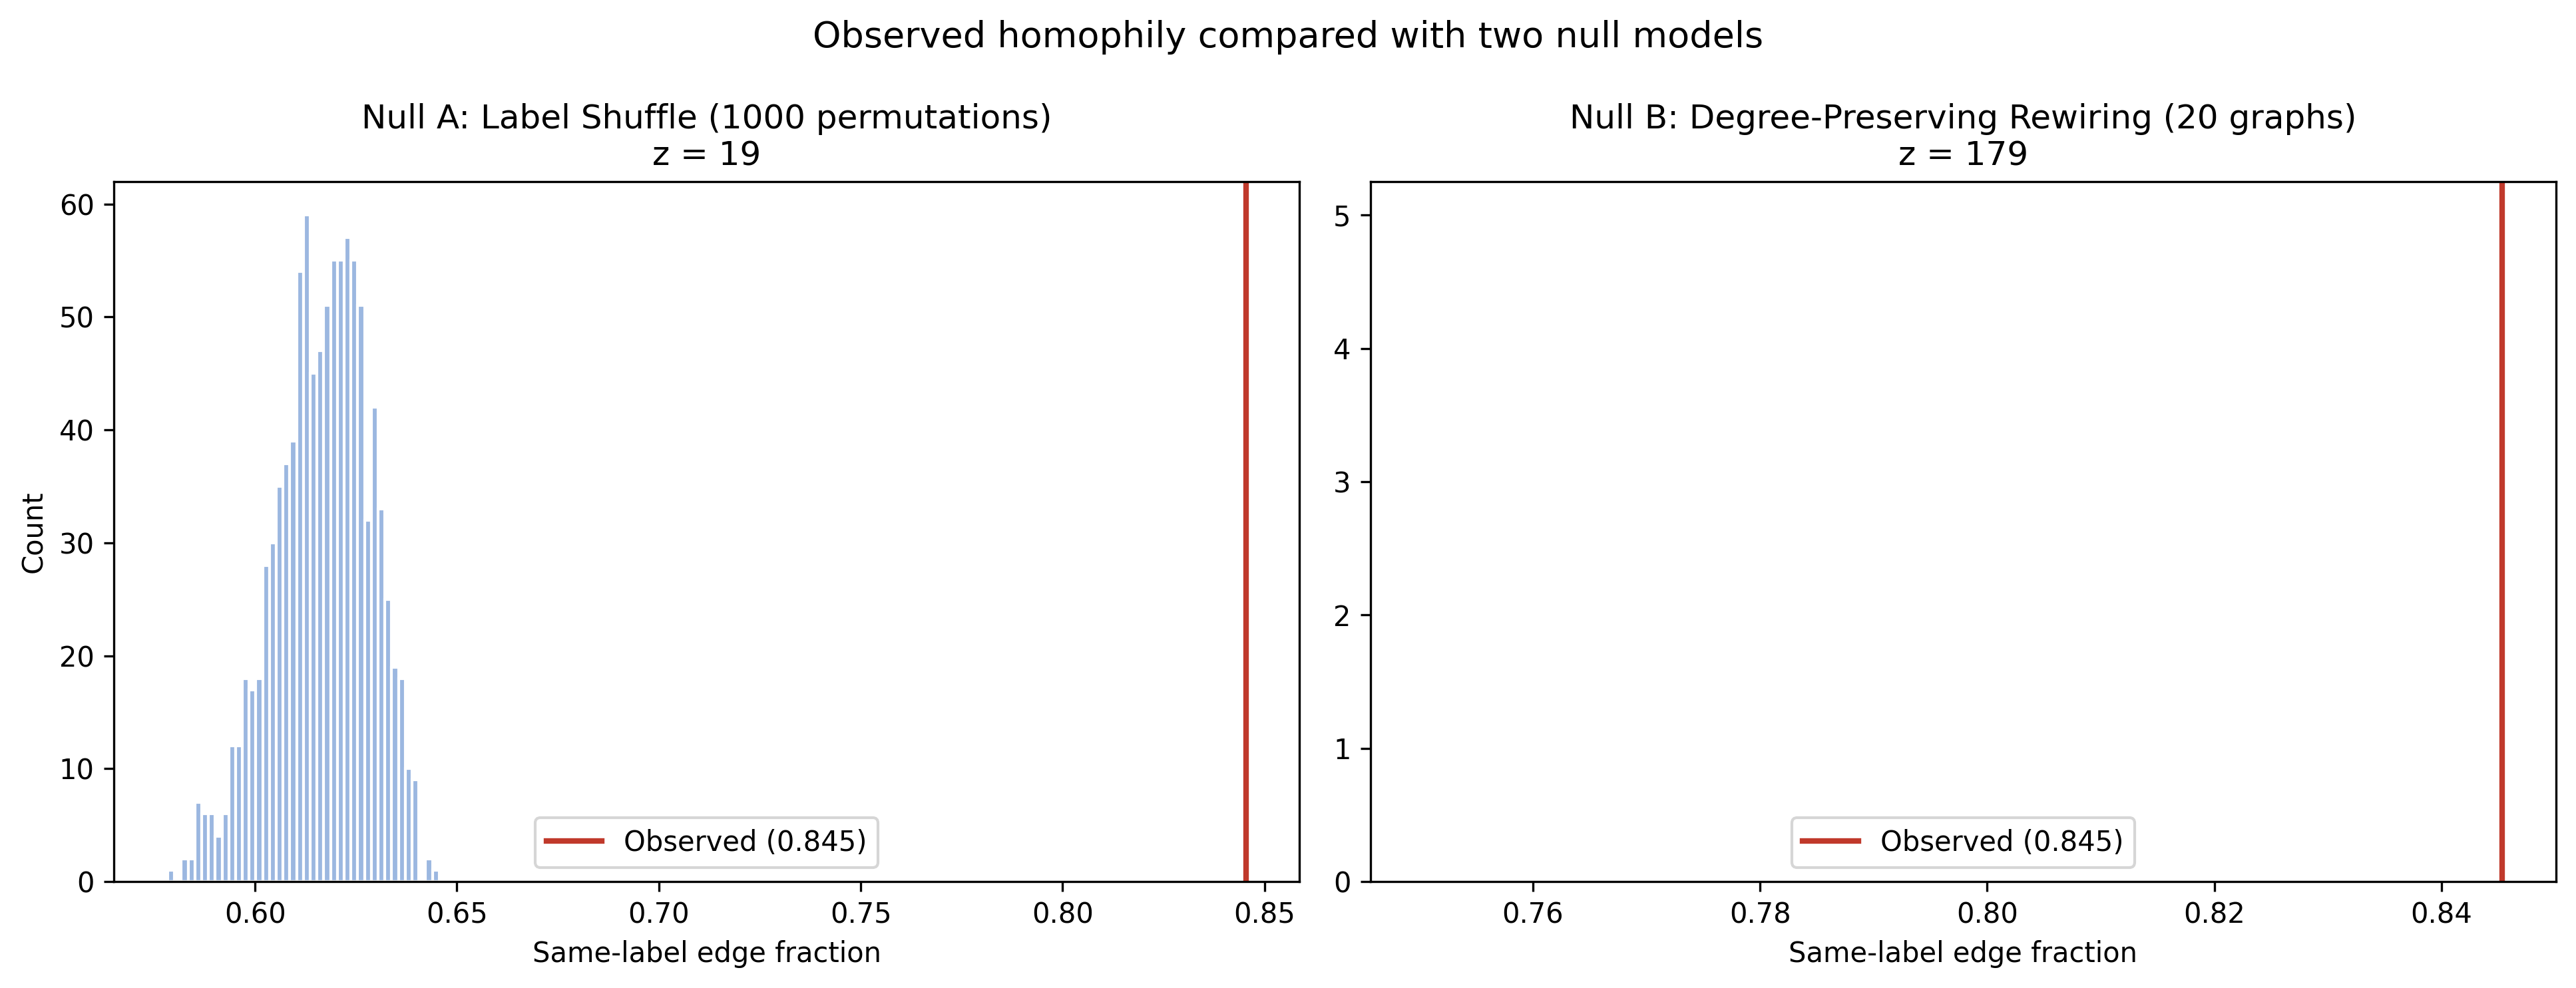

In [7]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / 'outputs/figures/homophily_null_distribution.png')))

**Figure note.** The real line is in the upper tail in both panels, supporting a stronger-than-random connection between field and structure without implying cause-and-effectity.

<h3>Table: <code>outputs/tables/null_model_modularity.csv</code></h3>

The Louvain community score in the real graph compared with rewired graphs.

In [8]:
modularity_null = pd.read_csv(ROOT / 'outputs/tables/null_model_modularity.csv')
display(modularity_null.round(6))

,observed_modularity,rewired_null_mean,rewired_null_std,z_score,n_rewires,empirical_p
0,0.453448,0.188541,0.000778,340.357861,20,0.047619


**Conclusion.** The real graph has stronger communities than the rewired graphs, so degree alone does not explain the pattern.

<h3>Table: <code>outputs/tables/network_vs_random_models.csv</code></h3>

The real graph compared with standard random graph families.

In [9]:
random_models = pd.read_csv(ROOT / 'outputs/tables/network_vs_random_models.csv')
display(random_models.round(4))

,network,nodes,edges,edge_count_difference_pct,max_degree,mean_degree,transitivity,avg_clustering,degree_assortativity,avg_shortest_path_sampled
0,GitHub observed,37700,289003,0.0000,9458,15.3317,0.0124,0.1675,-0.0752,3.2180
1,Erdos-Renyi,37700,289003,0.0000,34,15.3317,0.0004,0.0004,0.0011,4.1253
2,Barabasi-Albert (m=8),37700,301536,4.3366,891,15.9966,0.0027,0.0034,-0.0138,3.5895
3,"Watts-Strogatz (k=16, p=0.1)",37700,301600,4.3588,22,16.0000,0.5059,0.5117,-0.0045,5.5516
4,Degree-preserving configuration null,37700,289003,0.0000,9458,15.3317,0.0122,0.0914,-0.0713,3.1561


**Conclusion.** No single simple model reproduces hubs, clustering, path length, and degree heterogeneity simultaneously.

<h3>Table: <code>outputs/tables/powerlaw_fit.csv</code></h3>

Degree-tail comparisons among power law, exponential, and lognormal alternatives.

In [10]:
tail_fit = pd.read_csv(ROOT / 'outputs/tables/powerlaw_fit.csv')
display(tail_fit.round(4))

,alpha,xmin,sigma,loglik_ratio_vs_lognormal,p_vs_lognormal,loglik_ratio_vs_exponential,p_vs_exponential
0,2.5441,55.0,0.0378,0.0127,0.7826,605.7911,0.0


**Conclusion.** The tail is heavy and power law beats exponential, but it is not clearly distinguishable from lognormal; a unique scale-free claim is therefore unsupported.

<h2>Final conclusions</h2>

In [11]:
classification = pd.read_csv(ROOT / "outputs/tables/classification_summary.csv")
ablation = pd.read_csv(ROOT / "outputs/tables/ablation_model_results_summary.csv")
links = pd.read_csv(ROOT / "outputs/tables/edge_reconstruction_summary.csv")
homophily = pd.read_csv(ROOT / "outputs/tables/null_model_homophily.csv")
answers = pd.DataFrame([
    {"question": "1", "conclusion": "Graph structure predicts developer field well, but not perfectly.", "main_number": f"Best graph ROC-AUC: {classification.roc_auc_mean.max():.3f}"},
    {"question": "2", "conclusion": "Content is strong, and combining it with graph features works best.", "main_number": f"Best combined ROC-AUC: {ablation.roc_auc_mean.max():.3f}"},
    {"question": "3", "conclusion": "Hidden edges can be recovered from the graph better than random guessing.", "main_number": f"Best edge ROC-AUC: {links.roc_auc_mean.max():.3f}"},
    {"question": "4", "conclusion": "The real graph has stronger same-field linking than the random comparisons.", "main_number": f"Smallest p-value: {homophily.empirical_p.min():.6f}"},
])
display(answers)

,question,conclusion,main_number
0,1,"Graph structure predicts developer field well, but not perfectly.",Best graph ROC-AUC: 0.869
1,2,"Content is strong, and combining it with graph features works best.",Best combined ROC-AUC: 0.898
2,3,Hidden edges can be recovered from the graph better than random guessing.,Best edge ROC-AUC: 0.924
3,4,The real graph has stronger same-field linking than the random comparisons.,Smallest p-value: 0.000999


The four answers combine held-out prediction, controlled information comparisons, connected edge reconstruction, and explicit random baselines. Together they support a strong based on this dataset relationship between field and network structure, not a cause-and-effect claim.

<h2>Limits and notes</h2>

Limitations include the static June 2019 snapshot, a binary and potentially noisy target, approximate betweenness, fixed embedding budgets, and static reconstruction rather than temporal forecasting. Core references are MUSAE; Louvain; DeepWalk; Node2Vec; Liben-Nowell and Kleinberg on link prediction; Clauset, Shalizi, and Newman on power-law analysis; PageRank; and course material on centrality, communities, random graphs, reconstruction, and embeddings.

<h2>Summary</h2>

In this notebook we compared the real graph with random versions of the same problem. We checked whether same-field links and community structure are stronger than what we would expect after shuffling labels or rewiring edges. Then we pulled together the main answers from the earlier notebooks. This step helps separate strong real patterns from patterns that could appear by chance.